<a href="https://colab.research.google.com/github/renancarbonera04/portfolio/blob/main/02-manutencao-preditiva-knn/manutencao_preditiva_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏭 Manutenção Preditiva com KNN — AI4I 2020

**Objetivo:** Classificação binária — prever se um equipamento vai falhar (`Machine failure = 1`) ou operar normalmente (`Machine failure = 0`).

**Modelo:** K-Nearest Neighbors (KNN) com distância Euclidiana.

**Pipeline:**
- Pré-processamento e normalização (StandardScaler)
- Balanceamento de classes com SMOTE (apenas no treino)
- Seleção do hiperparâmetro K via validação cruzada estratificada (**Recall** da classe Falha)
- Avaliação no conjunto de teste
- Visualizações: curva K × Recall com linha de tendência, matriz de confusão e curva ROC
- Função de predição individual

**Dataset:** [AI4I 2020 — Kaggle](https://www.kaggle.com/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020)

> Os modos de falha individuais (TWF, HDF, PWF, OSF, RNF) são desconsiderados conforme requisito do trabalho.

In [ ]:
!pip install scikit-learn imbalanced-learn pandas matplotlib -q

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    ConfusionMatrixDisplay, roc_curve
)
from imblearn.over_sampling import SMOTE

os.makedirs('img', exist_ok=True)
print('✅ Bibliotecas carregadas!')

✅ Bibliotecas carregadas!


## ⚙️ Parâmetros — Altere aqui conforme necessário

In [3]:
# ============================================================
#  PARÂMETROS AJUSTÁVEIS
# ============================================================

# Amostra de 1.000 registros do dataset público AI4I 2020 (UCI / Kaggle)
CSV_PATH = 'data/ai4i2020_amostra_1000.csv'
if not os.path.exists(CSV_PATH):  # no Colab: baixa a amostra direto do GitHub
    CSV_PATH = ('https://raw.githubusercontent.com/renancarbonera04/portfolio/main/'
                '02-manutencao-preditiva-knn/data/ai4i2020_amostra_1000.csv')

TEST_SIZE    = 0.20   # ← proporção do conjunto de teste (ex: 0.20 = 20%)
RANDOM_STATE = 42
K_LISTA      = list(range(1, 30))   # ← ALTERE AQUI: lista de Ks a testar (ex: [1,3,5,7,10,15,20])
CV_FOLDS     = 5                    # ← número de folds na validação cruzada

TARGET    = 'Machine failure'
COLS_DROP = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

print(f'✅ Parâmetros | Test size: {TEST_SIZE:.0%} | Ks testados: {K_LISTA} | CV folds: {CV_FOLDS}')

✅ Parâmetros | Test size: 20% | Ks testados: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29] | CV folds: 5


## 📂 Carregamento dos Dados

In [4]:
df = pd.read_csv(CSV_PATH, sep=';')
print(f'▸ Shape original      : {df.shape}')
print(f'▸ Colunas             : {list(df.columns)}')
df.head(3)

▸ Shape original      : (1000, 14)
▸ Colunas             : ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,51,L47230,L,298.9,309.1,2861,4.6,143,1,0,0,1,0,0
1,70,L47249,L,298.9,309.0,1410,65.7,191,1,0,0,1,1,0
2,78,L47257,L,298.8,308.9,1455,41.3,208,1,1,0,0,0,0


## 🔧 Pré-processamento

In [5]:
# Remover identificadores e modos de falha individuais
df.drop(columns=[c for c in COLS_DROP if c in df.columns], inplace=True)

# Verificar valores ausentes
n_missing = df.isnull().sum().sum()
print(f'▸ Valores ausentes    : {n_missing}')

# Codificação da variável categórica Type (L, M, H → inteiro)
le = LabelEncoder()
df['Type'] = le.fit_transform(df['Type'])
print(f'▸ Encoding "Type"     : {dict(zip(le.classes_, le.transform(le.classes_)))}')

X = df.drop(columns=[TARGET])
y = df[TARGET]
FEATURE_NAMES = list(X.columns)

print(f'\n▸ Distribuição da variável-alvo:')
vc = y.value_counts().sort_index()
for cls, cnt in vc.items():
    label = 'Normal' if cls == 0 else 'Falha '
    print(f'    Classe {cls} ({label}): {cnt:5d}  ({cnt/len(y)*100:.2f}%)')

▸ Valores ausentes    : 0
▸ Encoding "Type"     : {'H': np.int64(0), 'L': np.int64(1), 'M': np.int64(2)}

▸ Distribuição da variável-alvo:
    Classe 0 (Normal):   661  (66.10%)
    Classe 1 (Falha ):   339  (33.90%)


## ✂️ Divisão Treino / Teste

Divisão estratificada (80/20), garantindo a mesma proporção de falhas em ambos os conjuntos.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f'▸ Treino : {len(X_train)} amostras  ({int(y_train.sum())} falhas)')
print(f'▸ Teste  : {len(X_test)} amostras  ({int(y_test.sum())} falhas)')

▸ Treino : 800 amostras  (271 falhas)
▸ Teste  : 200 amostras  (68 falhas)


## 📏 Normalização

O KNN é baseado em distância Euclidiana — a normalização é **obrigatória** para evitar que variáveis com escalas maiores dominem o cálculo.
O `StandardScaler` é ajustado apenas no treino e aplicado ao teste.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit apenas no treino
X_test_scaled  = scaler.transform(X_test)         # aplica mesma escala no teste
print('✅ Normalização concluída (StandardScaler)')

✅ Normalização concluída (StandardScaler)


## ⚖️ Balanceamento com SMOTE

O dataset é altamente desbalanceado (~3,4% de falhas). O SMOTE gera amostras sintéticas da classe minoritária **somente no treino**, evitando vazamento de dados.

In [8]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

u, c = np.unique(y_train_bal, return_counts=True)
print(f'▸ Após SMOTE — treino : {len(y_train_bal)} amostras')
for cls, cnt in zip(u, c):
    label = 'Normal' if cls == 0 else 'Falha '
    print(f'    Classe {cls} ({label}): {cnt}')

▸ Após SMOTE — treino : 1058 amostras
    Classe 0 (Normal): 529
    Classe 1 (Falha ): 529


## 🔍 Seleção do Hiperparâmetro K por Recall

Para cada K, o modelo é treinado com o conjunto de treino balanceado (pós-SMOTE) e avaliado diretamente no **conjunto de teste real** (sem SMOTE).

O Recall mede a proporção de falhas reais que o modelo consegue detectar:
$$\text{Recall} = \frac{VP}{VP + FN}$$

Maximizar o Recall é prioritário quando o custo de **não detectar uma falha** (falso negativo) é alto.

In [9]:
from sklearn.metrics import recall_score as _recall_score

print(f'▸ Testando K = {K_LISTA}')
print(f'▸ Métrica: Recall (classe Falha) avaliado no conjunto de TESTE\n')

rec_teste  = []

print(f'  {"K":>4}  {"Recall (Teste)":>16}  {"Resultado"}')
print('  ' + '-' * 45)

for k in K_LISTA:
    knn_k  = KNeighborsClassifier(n_neighbors=k, metric='euclidean',
                                   weights='uniform', algorithm='ball_tree')
    knn_k.fit(X_train_bal, y_train_bal)
    y_pred_k = knn_k.predict(X_test_scaled)
    rec      = _recall_score(y_test, y_pred_k)
    rec_teste.append(rec)
    barra = '█' * int(rec * 20)
    print(f'  K={k:2d}  {rec:.4f}            {barra}')

BEST_K      = K_LISTA[int(np.argmax(rec_teste))]
BEST_RECALL = max(rec_teste)
print(f'\n  ➤ Melhor K : {BEST_K}  (Recall Teste = {BEST_RECALL:.4f})')

▸ Testando K = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
▸ Métrica: Recall (classe Falha) avaliado no conjunto de TESTE

     K    Recall (Teste)  Resultado
  ---------------------------------------------
  K= 1  0.9265            ██████████████████
  K= 2  0.9118            ██████████████████
  K= 3  0.9265            ██████████████████
  K= 4  0.8824            █████████████████
  K= 5  0.9118            ██████████████████
  K= 6  0.8971            █████████████████
  K= 7  0.9412            ██████████████████
  K= 8  0.9118            ██████████████████
  K= 9  0.9265            ██████████████████
  K=10  0.9265            ██████████████████
  K=11  0.9265            ██████████████████
  K=12  0.9265            ██████████████████
  K=13  0.9265            ██████████████████
  K=14  0.9118            ██████████████████
  K=15  0.9265            ██████████████████
  K=16  0.8824            █████████████████
  K=17  0.88

  K=29  0.8971            █████████████████

  ➤ Melhor K : 7  (Recall Teste = 0.9412)


## 📈 Gráfico K × Recall com Linha de Tendência

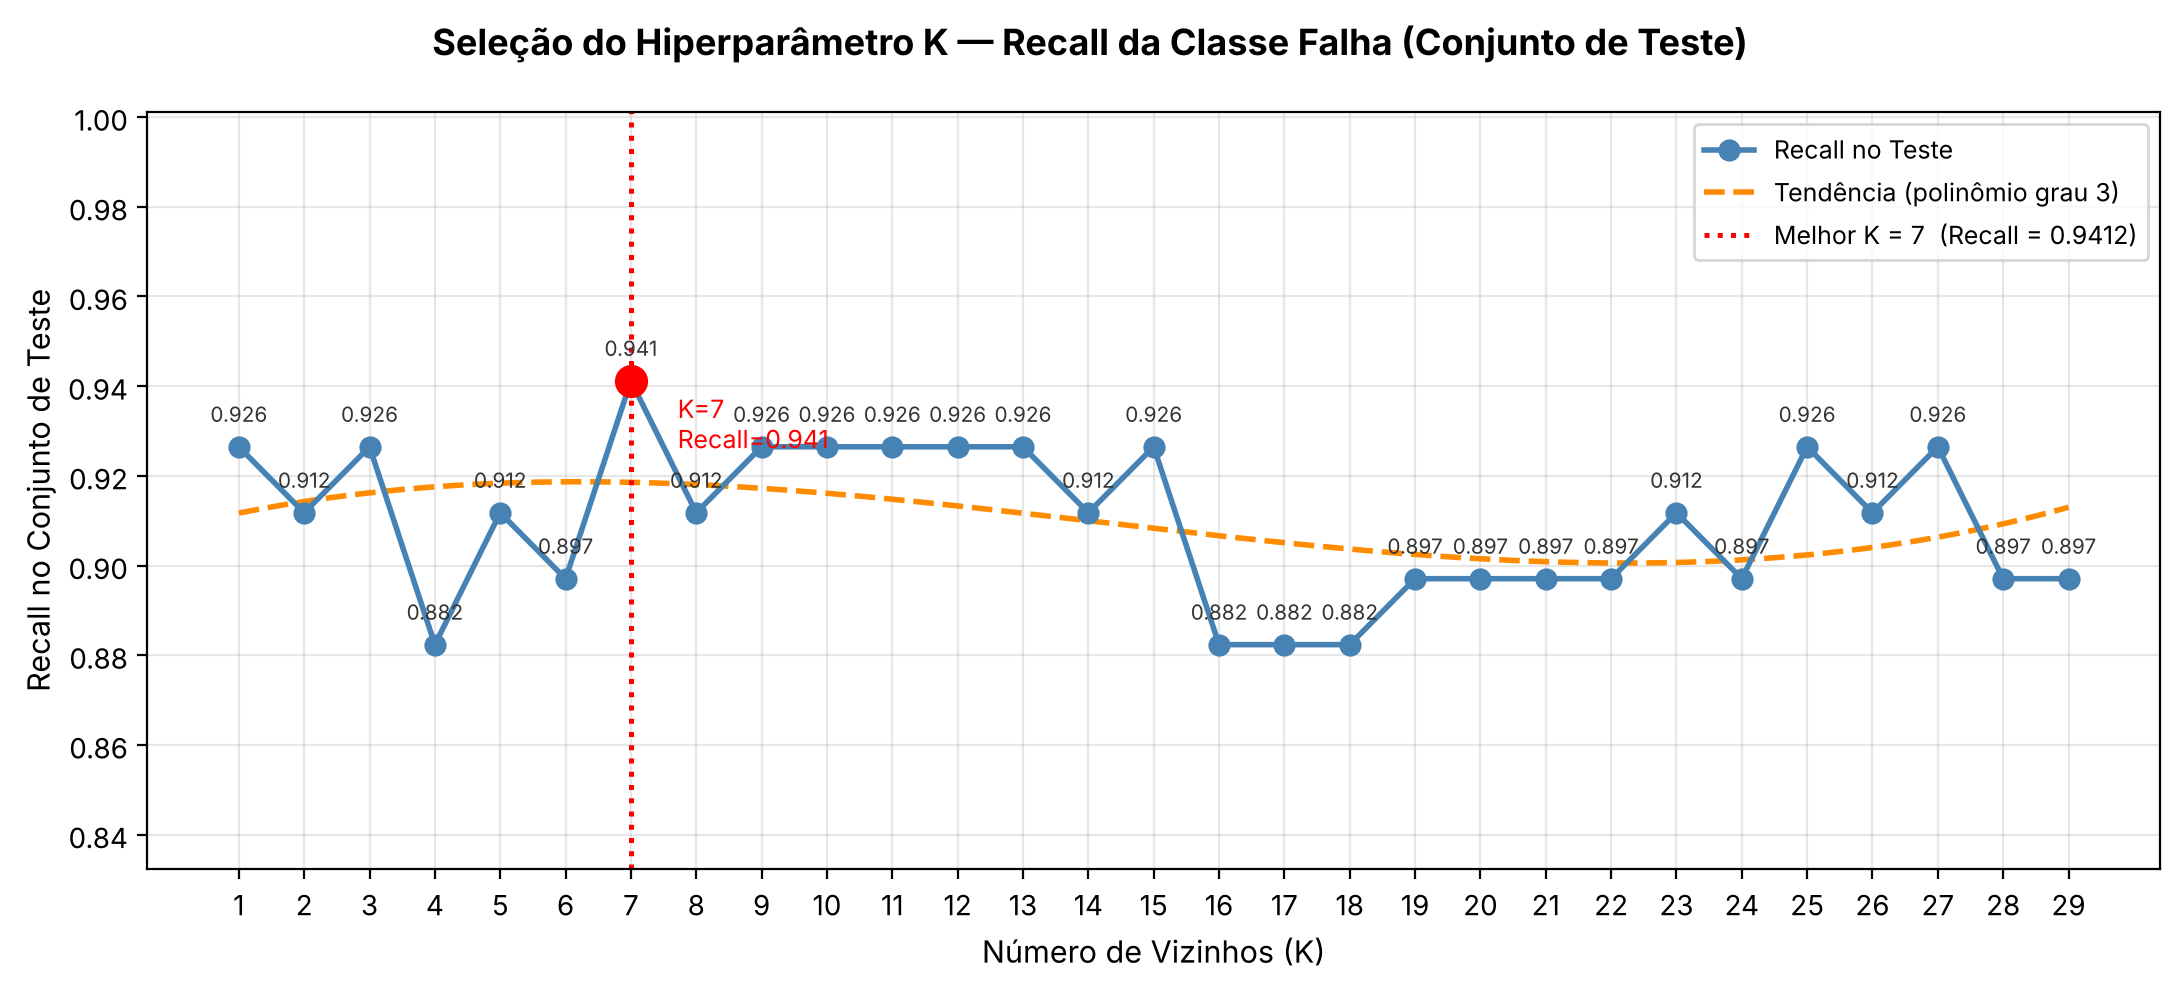

  Figura salva em: img/recall_por_k.png


In [10]:
k_arr  = np.array(K_LISTA)
rm_arr = np.array(rec_teste)

# Linha de tendência polinomial grau 3
coef   = np.polyfit(k_arr, rm_arr, deg=3)
k_fine = np.linspace(k_arr.min(), k_arr.max(), 300)
tend   = np.polyval(coef, k_fine)

fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle('Seleção do Hiperparâmetro K — Recall da Classe Falha (Conjunto de Teste)',
             fontsize=13, fontweight='bold')

# Pontos e linha dos recalls
ax.plot(k_arr, rm_arr, 'o-', color='steelblue',
        linewidth=2, markersize=7, label='Recall no Teste', zorder=3)

# Linha de tendência
ax.plot(k_fine, tend, '--', color='darkorange',
        linewidth=2, label='Tendência (polinômio grau 3)')

# Destaque do melhor K
ax.axvline(x=BEST_K, color='red', linestyle=':', linewidth=1.8,
           label=f'Melhor K = {BEST_K}  (Recall = {BEST_RECALL:.4f})')
ax.scatter([BEST_K], [BEST_RECALL], color='red', s=120, zorder=5)
ax.annotate(f'  K={BEST_K}\n  Recall={BEST_RECALL:.3f}',
            xy=(BEST_K, BEST_RECALL),
            xytext=(BEST_K + 0.5, BEST_RECALL - 0.015),
            fontsize=9, color='red')

# Anotações em cada ponto
for k, r in zip(k_arr, rm_arr):
    ax.annotate(f'{r:.3f}', xy=(k, r), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=7.5, color='#333')

ax.set_xlabel('Número de Vizinhos (K)', fontsize=11)
ax.set_ylabel('Recall no Conjunto de Teste', fontsize=11)
ax.set_xticks(k_arr)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(max(0, rm_arr.min() - 0.05), min(1.02, rm_arr.max() + 0.06))

plt.tight_layout()
plt.savefig('img/recall_por_k.png', dpi=150, bbox_inches='tight')
plt.show()
print('  Figura salva em: img/recall_por_k.png')

## 🤖 Treinamento do Modelo Final

In [11]:
knn_model = KNeighborsClassifier(
    n_neighbors = BEST_K,
    metric      = 'euclidean',
    weights     = 'uniform',
    algorithm   = 'ball_tree'   # eficiente para espaços normalizados
)
knn_model.fit(X_train_bal, y_train_bal)
print(f'✅ Modelo treinado — KNN com K={BEST_K}  (selecionado por Recall)')

✅ Modelo treinado — KNN com K=7  (selecionado por Recall)


## 📊 Avaliação no Conjunto de Teste

In [12]:
y_pred = knn_model.predict(X_test_scaled)
y_prob = knn_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
cm      = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

recall_teste    = tp / (tp + fn) if (tp + fn) > 0 else 0
precision_teste = tp / (tp + fp) if (tp + fp) > 0 else 0

print('=' * 60)
print('  RESULTADOS NO CONJUNTO DE TESTE')
print('=' * 60)
print(f'\n  Recall  (Falha)    : {recall_teste:.4f}')
print(f'  Precisão (Falha)   : {precision_teste:.4f}')
print(f'  ROC-AUC            : {roc_auc:.4f}')
print(f'\n  Matriz de Confusão :')
print(f'    VN={tn}  FP={fp}')
print(f'    FN={fn}   VP={tp}')
print(f'\n{classification_report(y_test, y_pred, target_names=["Normal (0)", "Falha (1)"])}')

  RESULTADOS NO CONJUNTO DE TESTE

  Recall  (Falha)    : 0.9412
  Precisão (Falha)   : 0.9275
  ROC-AUC            : 0.9807

  Matriz de Confusão :
    VN=127  FP=5
    FN=4   VP=64

              precision    recall  f1-score   support

  Normal (0)       0.97      0.96      0.97       132
   Falha (1)       0.93      0.94      0.93        68

    accuracy                           0.95       200
   macro avg       0.95      0.95      0.95       200
weighted avg       0.96      0.95      0.96       200



## 📉 Visualizações — Matriz de Confusão e Curva ROC

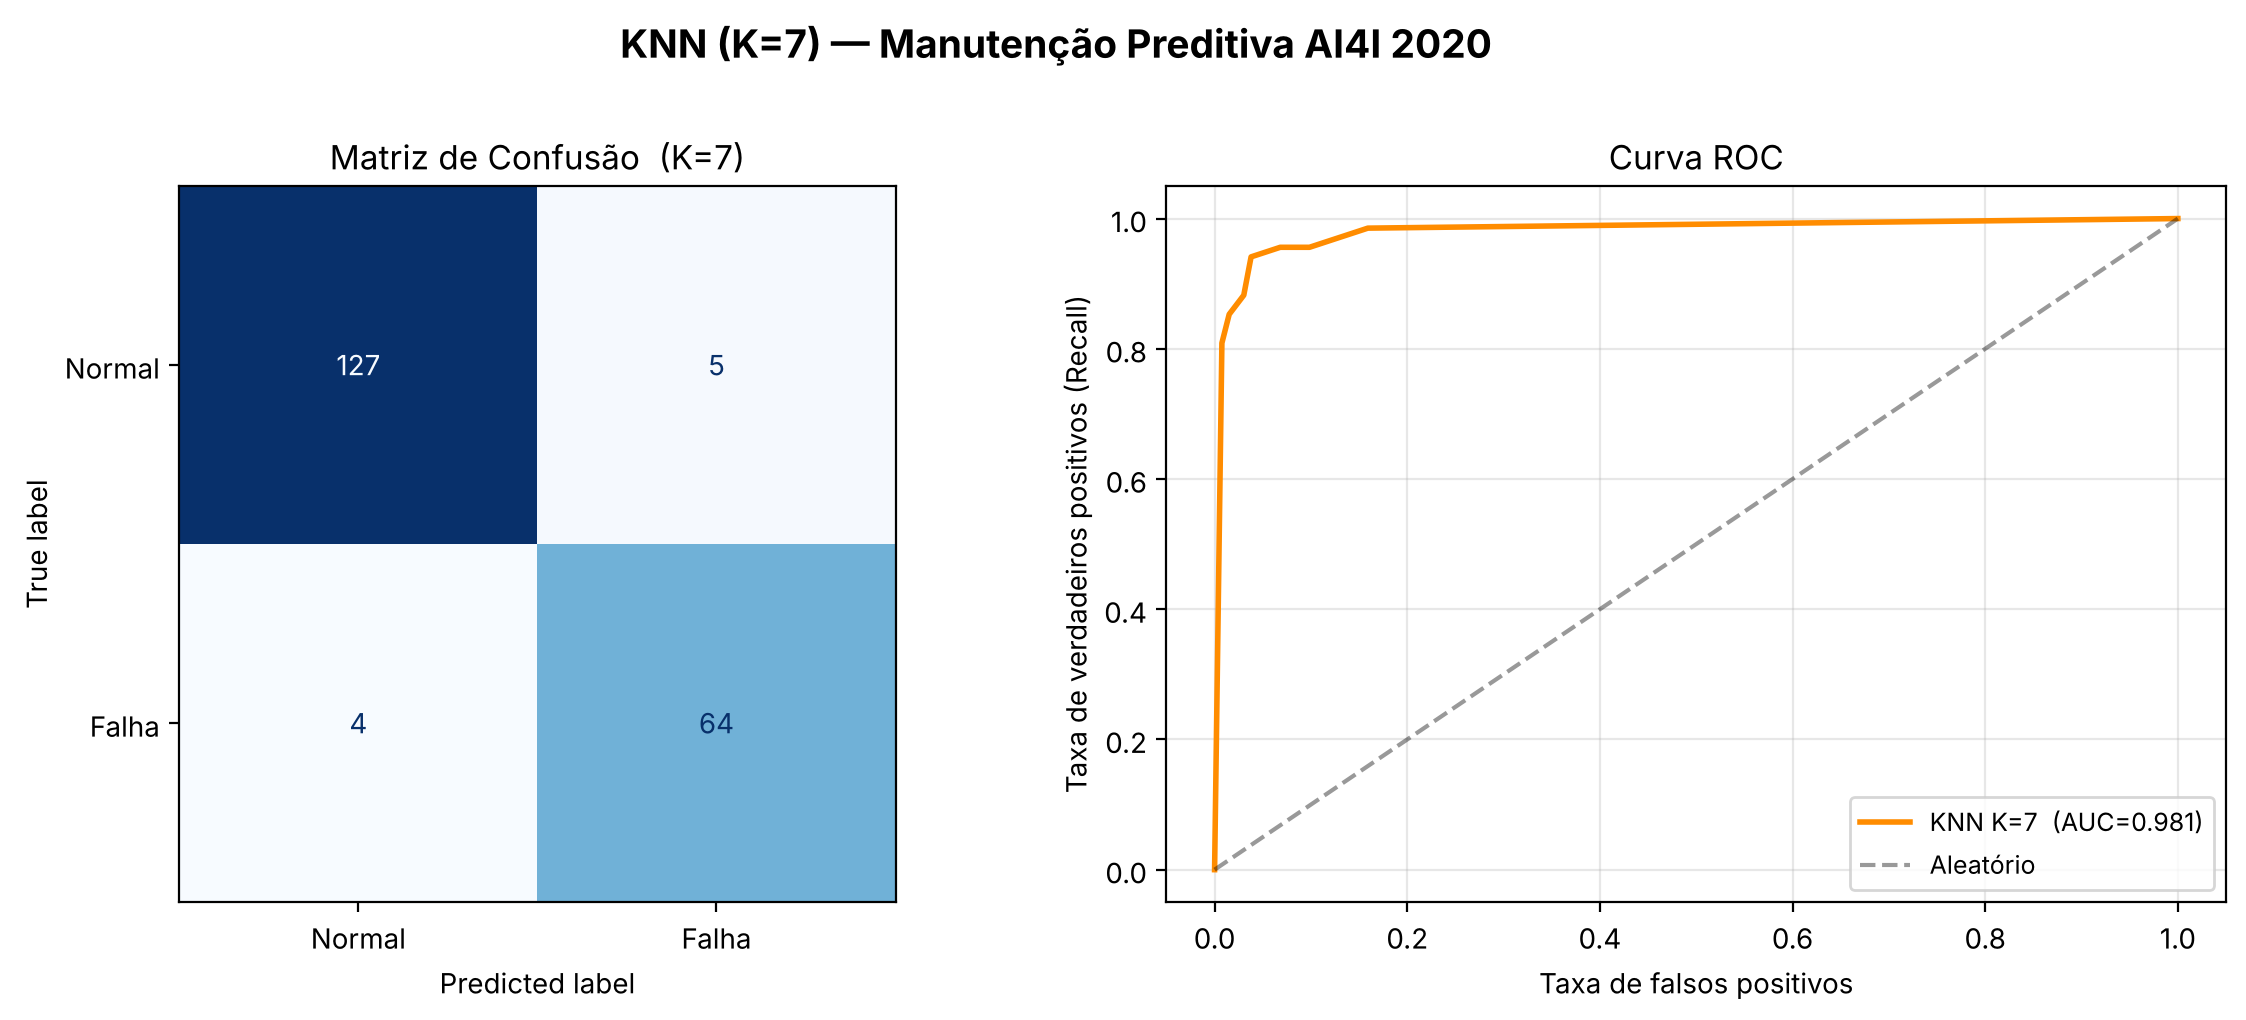

  Figura salva em: img/resultados_knn.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f'KNN (K={BEST_K}) — Manutenção Preditiva AI4I 2020',
             fontsize=14, fontweight='bold', y=1.01)

# --- Matriz de Confusão ---
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Falha'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Matriz de Confusão  (K={BEST_K})', fontsize=12)

# --- Curva ROC ---
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', linewidth=2,
             label=f'KNN K={BEST_K}  (AUC={roc_auc:.3f})')
axes[1].set_xlabel('Taxa de falsos positivos')
axes[1].set_ylabel('Taxa de verdadeiros positivos (Recall)')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Aleatório')
axes[1].set_title('Curva ROC', fontsize=12)
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('img/resultados_knn.png', dpi=150, bbox_inches='tight')
plt.show()
print('  Figura salva em: img/resultados_knn.png')

## 🔮 Predição Individual

Use a função abaixo para prever o status de um equipamento a partir das leituras dos sensores.

In [14]:
def prever_falha(tipo: str, temp_ar: float, temp_processo: float,
                 rpm: int, torque: float, desgaste: int) -> dict:
    """
    Prevê se um equipamento vai falhar com base nas leituras dos sensores.

    Parâmetros
    ----------
    tipo          : Tipo do produto — 'L' (low), 'M' (medium), 'H' (high)
    temp_ar       : Temperatura do ar [K]         (ex: 298.1)
    temp_processo : Temperatura do processo [K]   (ex: 308.6)
    rpm           : Velocidade rotacional [rpm]   (ex: 1551)
    torque        : Torque [Nm]                   (ex: 42.8)
    desgaste      : Desgaste da ferramenta [min]  (ex: 120)

    Retorna
    -------
    dict com predição binária, status, probabilidade de falha e K utilizado.
    """
    tipo_enc   = le.transform([tipo])[0]
    X_new      = np.array([[tipo_enc, temp_ar, temp_processo, rpm, torque, desgaste]])
    X_scaled   = scaler.transform(X_new)
    pred       = knn_model.predict(X_scaled)[0]
    prob_falha = knn_model.predict_proba(X_scaled)[0][1]
    return {
        'predicao'           : int(pred),
        'status'             : '⚠️  FALHA PREVISTA' if pred == 1 else '✅  OPERAÇÃO NORMAL',
        'probabilidade_falha': f'{prob_falha * 100:.1f}%',
        'K_utilizado'        : BEST_K,
    }

print('✅ Função prever_falha() disponível!')

✅ Função prever_falha() disponível!


## 🧪 Exemplos de Predição

In [15]:
print('=' * 60)
print('  EXEMPLOS DE PREDIÇÃO INDIVIDUAL')
print('=' * 60)

# Equipamento em condição normal
print('\n  [Equipamento em condição normal]')
r1 = prever_falha(tipo='M', temp_ar=298.1, temp_processo=308.6, rpm=1551, torque=42.8, desgaste=0)
for chave, valor in r1.items():
    print(f'  {chave:<25}: {valor}')

# Equipamento em estado crítico
print('\n  [Equipamento com alto desgaste e alto torque]')
r2 = prever_falha(tipo='L', temp_ar=295.0, temp_processo=303.5, rpm=1200, torque=65.0, desgaste=220)
for chave, valor in r2.items():
    print(f'  {chave:<25}: {valor}')

  EXEMPLOS DE PREDIÇÃO INDIVIDUAL

  [Equipamento em condição normal]
  predicao                 : 0
  status                   : ✅  OPERAÇÃO NORMAL
  probabilidade_falha      : 0.0%
  K_utilizado              : 7

  [Equipamento com alto desgaste e alto torque]
  predicao                 : 1
  status                   : ⚠️  FALHA PREVISTA
  probabilidade_falha      : 100.0%
  K_utilizado              : 7


## 🏁 Conclusão Final

In [16]:
print('=' * 65)
print('  CONCLUSÃO — MANUTENÇÃO PREDITIVA COM KNN')
print('=' * 65)
print(f'  Dataset               : AI4I 2020')
print(f'  Amostras totais       : {len(df)}')
print(f'  Features utilizadas   : {FEATURE_NAMES}')
print(f'  Proporção treino/teste: {1 - TEST_SIZE:.0%} / {TEST_SIZE:.0%}')
print(f'  Balanceamento         : SMOTE')
print(f'  Métrica de seleção    : Recall no conjunto de Teste — classe Falha')
print(f'  Ks testados           : {K_LISTA}')
print()
print(f'  🏆 Melhor K           : {BEST_K}')
print(f'  Recall (Teste)        : {recall_teste:.4f}')
print(f'  Precisão (Teste)      : {precision_teste:.4f}')
print(f'  ROC-AUC (Teste)       : {roc_auc:.4f}')
print(f'  Verdadeiros Negativos : {tn}')
print(f'  Falsos Positivos      : {fp}')
print(f'  Falsos Negativos      : {fn}')
print(f'  Verdadeiros Positivos : {tp}')
print('=' * 65)
print('\n  Script concluído com sucesso!')

  CONCLUSÃO — MANUTENÇÃO PREDITIVA COM KNN
  Dataset               : AI4I 2020
  Amostras totais       : 1000
  Features utilizadas   : ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
  Proporção treino/teste: 80% / 20%
  Balanceamento         : SMOTE
  Métrica de seleção    : Recall no conjunto de Teste — classe Falha
  Ks testados           : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]

  🏆 Melhor K           : 7
  Recall (Teste)        : 0.9412
  Precisão (Teste)      : 0.9275
  ROC-AUC (Teste)       : 0.9807
  Verdadeiros Negativos : 127
  Falsos Positivos      : 5
  Falsos Negativos      : 4
  Verdadeiros Positivos : 64

  Script concluído com sucesso!
